# What drives GPU compute prices?

This analysis is purely data-driven, where we primarily look at correlation across different time-series.
1. How have prices moved for each GPU?
2. Do the GPUs move together? (If a shared cost like electricity drove prices, they should.)
3. When H100 prices jumped, what else moved that week?
4. Does anything tend to move a few weeks **before** GPU prices?

In [3]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import matplotlib.pyplot as plt
from ornn_analysis.explore import *
from ornn_analysis.series import DRIVERS

pd.set_option("display.precision", 2)
gpus = load_gpus()          # daily $/GPU-hour per GPU, from Ornn
drivers = load_drivers()    # gas, oil, stocks, rates... (see series.py)
changes = pct_change(pd.concat([gpus, drivers], axis=1))   # week-on-week % changes

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/3240145310.py:11: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  changes = pct_change(pd.concat([gpus, drivers], axis=1))   # week-on-week % changes


## 1 · Prices per GPU

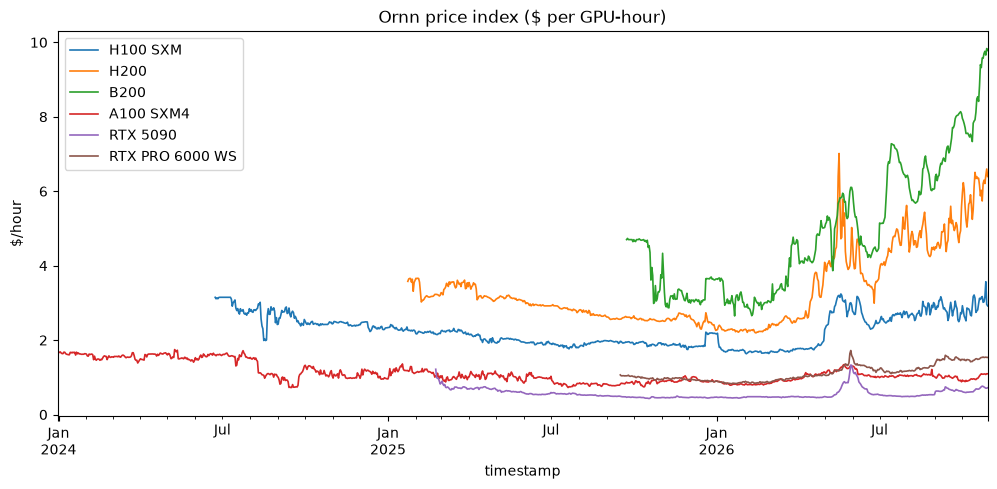

,data_from,first_price,latest_price,change_%
H100 SXM,2024-06-23,3.15,2.92,-7.30
H200,2025-01-23,3.58,6.39,78.73
B200,2025-09-23,4.70,9.79,108.19
A100 SXM4,2023-12-31,1.63,1.09,-32.90
RTX 5090,2025-02-23,1.22,0.72,-40.84
RTX PRO 6000 WS,2025-09-16,1.06,1.53,44.13


In [4]:
ax = gpus.plot(figsize=(12, 5), lw=1.2, title="Ornn price index ($ per GPU-hour)")
ax.set_ylabel("$/hour"); plt.show()

summary = pd.DataFrame({
    "data_from": gpus.apply(lambda s: s.first_valid_index().date()),
    "first_price": gpus.apply(lambda s: s.dropna().iloc[0]),
    "latest_price": gpus.apply(lambda s: s.dropna().iloc[-1]),
})
summary["change_%"] = 100 * (summary["latest_price"] / summary["first_price"] - 1)
summary

**What to look for:** do all GPUs head the same way? If one cost (power, rates) drove prices, they should. If newer and older chips move in opposite directions, the cause is specific to each GPU: demand for that chip, or supply of it.

## 2 · Do GPUs move together?
Correlation of **weekly % changes** between GPUs. 1 = always move together, 0 = unrelated.

In [5]:
changes[gpus.columns].corr().round(2)

,H100 SXM,H200,B200,A100 SXM4,RTX 5090,RTX PRO 6000 WS
H100 SXM,1.00,0.20,0.34,0.16,0.17,0.15
H200,0.20,1.00,0.16,-0.03,0.04,-0.19
B200,0.34,0.16,1.00,0.14,0.22,0.15
A100 SXM4,0.16,-0.03,0.14,1.00,0.19,0.11
RTX 5090,0.17,0.04,0.22,0.19,1.00,0.63
RTX PRO 6000 WS,0.15,-0.19,0.15,0.11,0.63,1.00


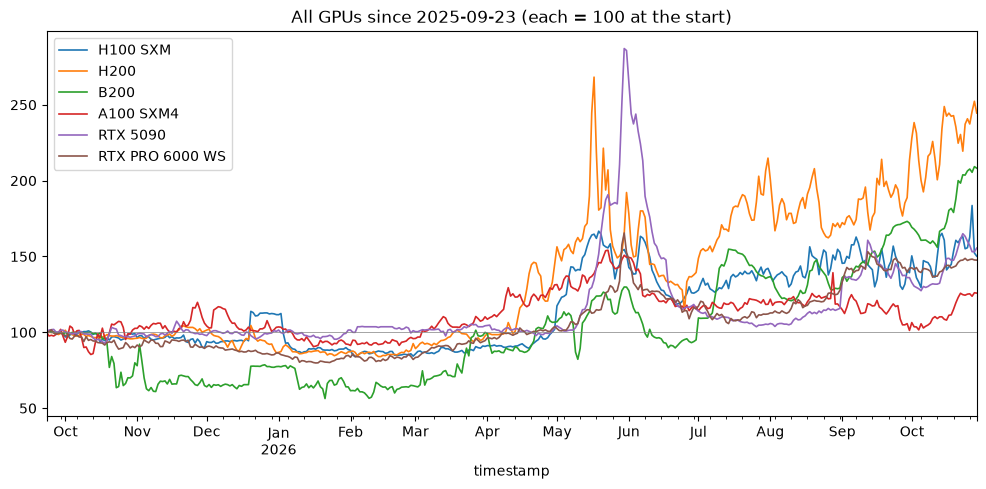

In [6]:
common_start = gpus.apply(lambda s: s.first_valid_index()).max()
ax = rebase(gpus, common_start).plot(figsize=(12, 5), lw=1.2,
        title=f"All GPUs since {common_start.date()} (each = 100 at the start)")
ax.axhline(100, color="grey", lw=0.5); plt.show()

### Price relative to H100
How many H100-hours one hour of each GPU costs. A rising line means that GPU is getting more expensive compared with an H100.

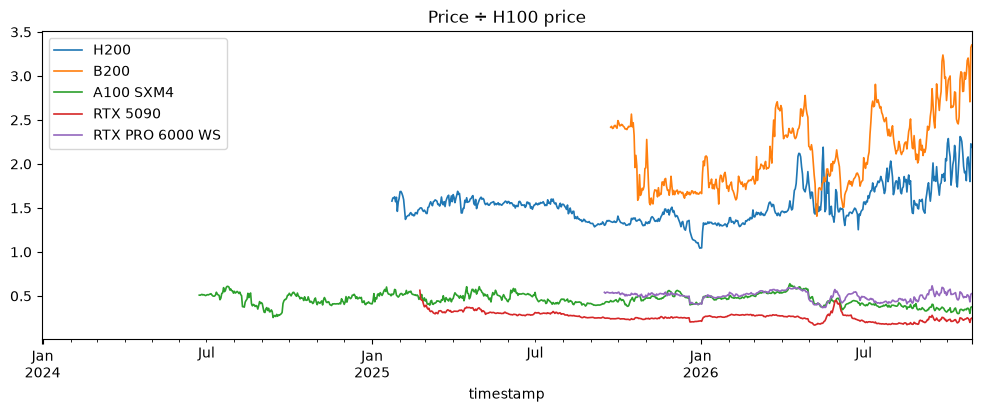

In [7]:
(gpus.div(gpus["H100 SXM"], axis=0).drop(columns="H100 SXM")
     .plot(figsize=(12, 4), lw=1.2, title="Price ÷ H100 price")); plt.show()

## 3 · H100's biggest weeks, and what else moved
The largest weekly moves in the H100 price. For each one, the table below shows what every other series did that week and the two weeks before.

In [8]:
TARGET = "B200"
moves = biggest_moves(gpus[TARGET])
moves

,week_ending,change_%,price_after
0,2026-03-27,33.8,4.77
1,2025-10-24,-32.7,3.02
2,2026-07-10,30.1,6.68
3,2025-10-31,24.4,3.76
4,2025-11-07,-20.4,2.99
5,2025-12-26,20.0,3.70
6,2026-04-24,18.4,4.83
7,2026-10-23,18.0,9.58


In [9]:
for week in moves["week_ending"][:4]:
    print(f"\n=== Week ending {week} ===")
    display(what_else_moved(changes, week))


=== Week ending 2026-03-27 ===


,2026-03-13,2026-03-20,2026-03-27
H100 SXM,4.4,-2.9,3.6
H200,2.2,6.0,-5.2
B200,7.6,2.2,33.8
A100 SXM4,9.2,-6.5,7.0
RTX 5090,-1.1,0.9,3.6
RTX PRO 6000 WS,4.2,1.8,3.8
henry_hub_gas,-1.7,-1.1,0.0
wti_oil,8.6,-0.4,1.3
brent_oil,11.3,8.8,0.3
nvidia,1.4,-4.2,-3.0



=== Week ending 2025-10-24 ===


,2025-10-10,2025-10-17,2025-10-24
H100 SXM,2.3,-5.1,0.9
H200,-1.7,-0.4,0.6
B200,0.8,-4.2,-32.7
A100 SXM4,-13.2,13.7,4.4
RTX 5090,-0.4,-5.2,4.8
RTX PRO 6000 WS,1.2,-4.4,-4.2
henry_hub_gas,-6.6,-3.2,9.8
wti_oil,-3.3,-2.3,6.9
brent_oil,-2.8,-2.3,7.6
nvidia,-2.4,0.0,1.7



=== Week ending 2026-07-10 ===


,2026-06-26,2026-07-03,2026-07-10
H100 SXM,1.7,8.0,-4.6
H200,-0.2,16.3,5.2
B200,4.7,14.2,30.1
A100 SXM4,-3.8,-0.3,-1.2
RTX 5090,-7.7,-3.5,-2.9
RTX PRO 6000 WS,-6.5,5.0,-7.4
henry_hub_gas,-0.1,-1.1,-8.0
wti_oil,-9.6,-0.8,4.0
brent_oil,-9.8,-0.3,5.9
nvidia,-8.6,1.2,8.3



=== Week ending 2025-10-31 ===


,2025-10-17,2025-10-24,2025-10-31
H100 SXM,-5.1,0.9,3.0
H200,-0.4,0.6,-1.5
B200,-4.2,-32.7,24.4
A100 SXM4,13.7,4.4,-4.3
RTX 5090,-5.2,4.8,-0.7
RTX PRO 6000 WS,-4.4,-4.2,1.1
henry_hub_gas,-3.2,9.8,24.8
wti_oil,-2.3,6.9,-0.8
brent_oil,-2.3,7.6,-1.3
nvidia,0.0,1.7,8.7


**What to look for:** if a driver moved strongly in the weeks **before** a big H100 move, it might lead. If nothing moved, the cause is probably specific to the GPU market (or a data glitch: a big drop followed straight away by a big rise is worth asking Ornn about).

## 4 · H100 next to each group of drivers
All rebased to 100 at the start of the H100 data. Thick black line = H100.

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/404943113.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = rebase(pd.concat([gpus[TARGET], drivers[names]], axis=1), gpus[TARGET].first_valid_index())


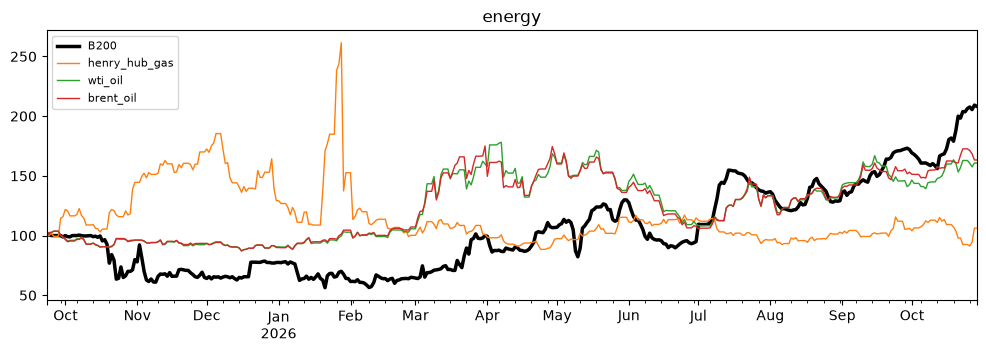

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/404943113.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = rebase(pd.concat([gpus[TARGET], drivers[names]], axis=1), gpus[TARGET].first_valid_index())


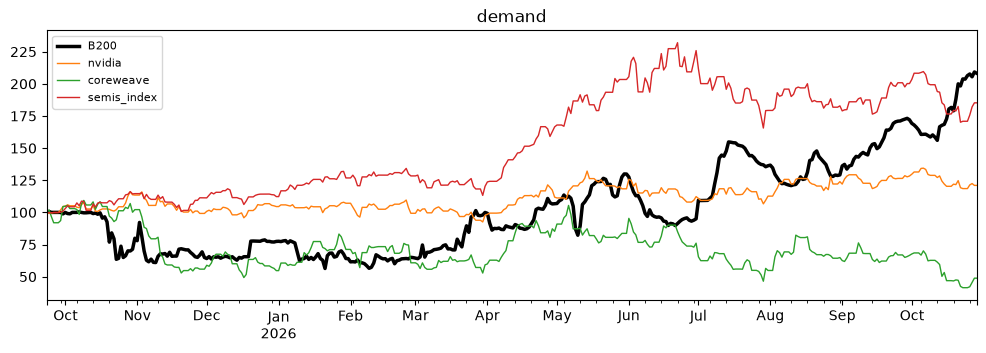

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/404943113.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = rebase(pd.concat([gpus[TARGET], drivers[names]], axis=1), gpus[TARGET].first_valid_index())


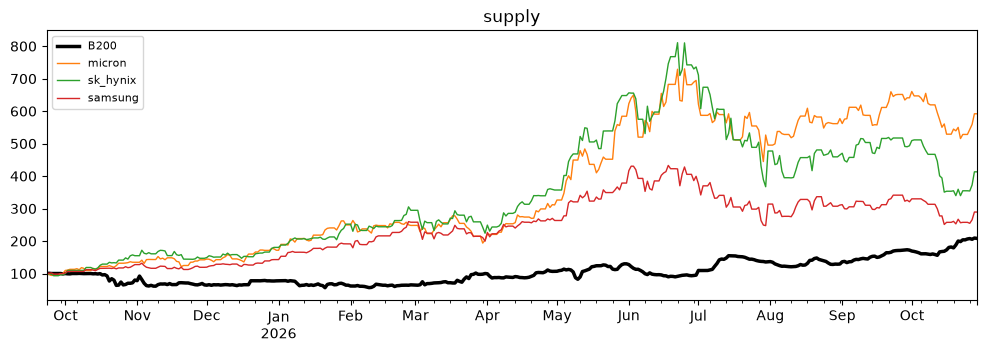

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/404943113.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = rebase(pd.concat([gpus[TARGET], drivers[names]], axis=1), gpus[TARGET].first_valid_index())


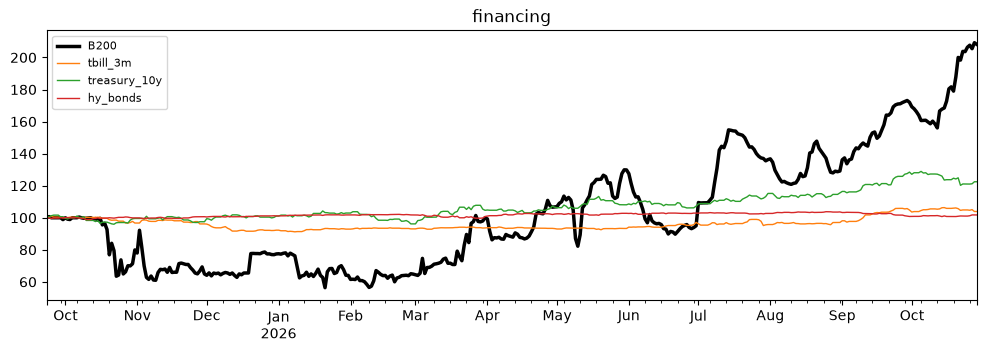

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/404943113.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = rebase(pd.concat([gpus[TARGET], drivers[names]], axis=1), gpus[TARGET].first_valid_index())


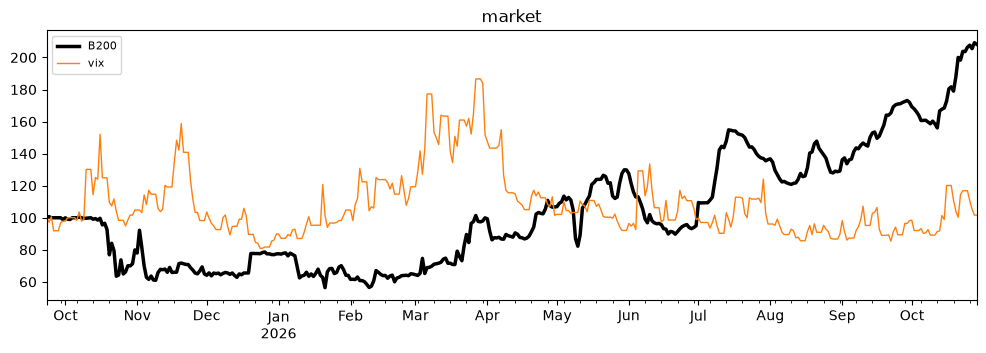

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/404943113.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = rebase(pd.concat([gpus[TARGET], drivers[names]], axis=1), gpus[TARGET].first_valid_index())


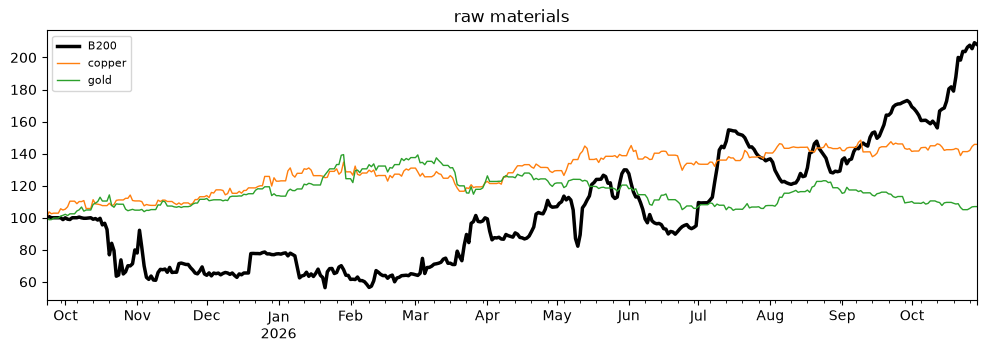

In [10]:
groups = {}
for name, (_, _, group, _) in DRIVERS.items():
    if name in drivers:
        groups.setdefault(group, []).append(name)
for group, names in groups.items():
    df = rebase(pd.concat([gpus[TARGET], drivers[names]], axis=1), gpus[TARGET].first_valid_index())
    ax = df.plot(figsize=(12, 3.5), lw=1, title=group)
    ax.get_lines()[0].set(lw=2.5, color="black"); ax.legend(fontsize=8, loc="upper left"); plt.show()

## 5 · Does anything move before H100 prices?
Each cell: correlation between that series' weekly change and the H100's weekly change **k weeks later**.
- **Positive k:** the series moved first, so it might lead H100.
- **Negative k:** H100 moved first.
- **k = 0:** same week.

Cells outside the *noise band* are coloured. Expect about 1 in 20 cells to be coloured by pure chance, so a single coloured cell means little. Look for a series with **several** coloured cells at nearby positive lags, ideally with the expected sign (higher costs, then higher prices). The raw-materials rows are a sanity check: they shouldn't matter, so they show what chance looks like.

In [11]:
lc = lag_correlations(changes[TARGET], changes[drivers.columns])
band = noise_band(changes[TARGET].count())
print(f"Noise band: ±{band:.2f}")
lc.style.format("{:.2f}").map(lambda v: f"background-color: {'#f4a6a6' if v < -band else '#9fd6a3' if v > band else ''}")

Noise band: ±0.26


,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10,11,12
henry_hub_gas,0.04,0.06,-0.16,0.17,0.07,-0.05,-0.10,-0.19,0.11,-0.06,-0.14,0.04,-0.01,-0.06,-0.02,0.06,-0.02,0.33,-0.19,-0.12,-0.09
wti_oil,0.04,0.06,-0.19,-0.10,-0.09,-0.04,0.01,0.25,0.12,0.07,-0.10,0.21,-0.15,0.04,-0.12,0.14,0.16,0.15,0.18,0.03,-0.28
brent_oil,0.06,0.04,-0.19,-0.13,-0.07,-0.05,0.01,0.18,0.21,0.15,-0.14,0.11,-0.11,0.11,-0.13,0.06,0.13,0.22,0.24,0.05,-0.28
nvidia,-0.05,0.23,-0.06,0.00,0.18,-0.02,0.26,-0.17,0.01,0.06,0.01,-0.07,-0.03,-0.13,-0.05,0.10,-0.09,0.07,0.05,-0.11,0.19
coreweave,-0.12,0.10,-0.20,0.27,0.08,0.27,0.14,-0.10,-0.17,-0.04,-0.00,0.04,0.09,-0.20,0.09,-0.00,-0.23,0.02,0.21,-0.18,0.35
semis_index,0.03,0.07,0.01,0.02,0.35,-0.06,0.26,-0.13,-0.18,-0.11,0.03,-0.07,0.23,-0.16,0.01,-0.11,-0.14,0.00,0.06,-0.00,0.17
micron,-0.05,0.12,0.08,0.08,0.30,-0.25,0.19,-0.06,-0.25,-0.07,0.07,-0.17,0.14,-0.27,0.01,-0.08,-0.08,0.16,0.10,-0.04,0.15
sk_hynix,0.12,0.03,0.11,0.17,0.07,-0.11,0.01,-0.14,-0.11,-0.09,-0.03,-0.03,0.07,-0.25,0.00,-0.13,0.03,0.29,-0.12,-0.00,0.18
samsung,0.08,-0.08,0.06,0.20,-0.02,-0.02,0.18,-0.21,-0.06,-0.16,-0.18,0.04,0.08,-0.14,0.13,-0.17,0.05,0.15,0.06,-0.10,0.15
tbill_3m,0.22,0.06,-0.06,-0.03,0.04,-0.06,0.03,0.11,0.06,0.17,0.01,-0.16,0.18,0.13,0.18,0.30,-0.09,0.17,0.16,0.05,-0.05


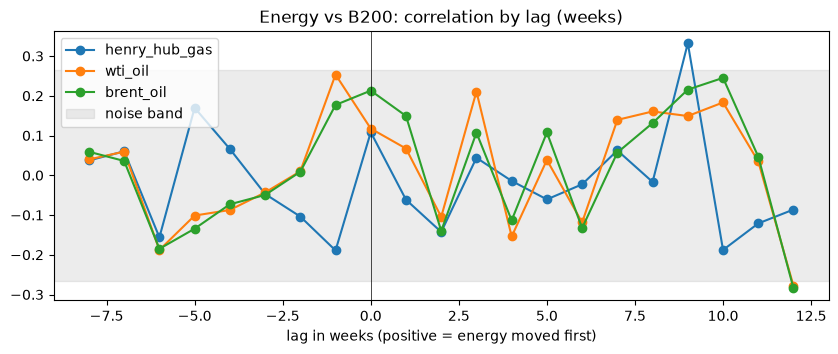

In [12]:
ax = lc.loc[["henry_hub_gas", "wti_oil", "brent_oil"]].T.plot(marker="o", figsize=(10, 3.5),
        title=f"Energy vs {TARGET}: correlation by lag (weeks)")
ax.axhspan(-band, band, color="grey", alpha=0.15, label="noise band"); ax.axvline(0, color="k", lw=0.5)
ax.set_xlabel("lag in weeks (positive = energy moved first)"); ax.legend(); plt.show()

### Is a bump real?
1. **Chance test:** We slide the driver to random dates 2,000 times and count how often a correlation this strong shows up. Under 5% = unlikely to be luck. (Similar to finding statistical significance)
2. **One event or a pattern?** If removing a single week makes the correlation collapse, it's one coincidence, not a repeatable link. Think the price increase after Strait of Hormuz closure
3. **Same lag for other GPUs?** A cost like energy hits every GPU, so the effect should show up for all of them.

In [13]:
DRIVER, LAG = "wti_oil", 9
print(chance_test(changes[TARGET], changes[DRIVER], LAG))
wc = week_contributions(changes[TARGET], changes[DRIVER], LAG)
print("Correlation without the top week:", wc.attrs["without_top_week"])
display(wc)
pd.Series({g: round(changes[g].corr(changes[DRIVER].shift(LAG)), 2) for g in gpus.columns}, name=f"corr with {DRIVER} {LAG}w earlier")

{'corr': np.float64(0.15), 'chance_at_this_lag_%': np.float64(27.6), 'chance_at_any_lag_%': np.float64(100.0)}
Correlation without the top week: 0.11


,adds_to_corr,other_9w_earlier_%,target_%
2026-06-12,0.04,-13.42,-14.38
2026-08-28,0.03,-9.62,-13.40
2025-12-26,0.02,6.88,19.97
2026-06-19,0.02,-13.17,-5.54
2025-11-07,0.02,-3.34,-20.37


H100 SXM           0.32
H200               0.15
B200               0.15
A100 SXM4         -0.08
RTX 5090           0.13
RTX PRO 6000 WS   -0.02
Name: corr with wti_oil 9w earlier, dtype: float64

Here we see that the correlation is not consistent with WTI.

## 6 · Big moves: zoom in and find out what happened
Every period where a GPU moved more than 15% within 14 days.
- **biggest_day_%**: share of the move that happened on one day. High = a sudden step (one repricing, a listing change, or a data issue). Low = a gradual climb (demand building).
- **after_30d_%**: where the price was 30 days after the peak, vs the start. Close to 0 = the move fully reversed.

In [14]:
episodes = all_episodes(gpus, window=14, threshold=15)
episodes

,gpu,start,peak,days,from_$,to_$,move_%,biggest_day_%,after_30d_%
0,A100 SXM4,2024-03-29,2024-04-12,14,1.38,1.63,17.5,63.0,24.8
1,A100 SXM4,2024-05-12,2024-05-26,14,1.73,1.46,-15.2,87.0,-6.9
2,A100 SXM4,2024-07-16,2024-07-24,8,1.31,1.72,31.4,44.0,-18.0
3,H100 SXM,2024-08-12,2024-08-18,6,3.02,1.99,-34.1,43.0,-7.9
4,H100 SXM,2024-09-10,2024-09-24,14,2.89,2.45,-15.1,40.0,-16.3
5,A100 SXM4,2024-12-25,2025-01-17,23,0.95,1.36,43.2,46.0,21.5
6,H200,2025-02-03,2025-02-07,4,3.66,3.02,-17.4,42.0,-6.0
7,A100 SXM4,2025-02-08,2025-03-06,26,1.24,0.88,-29.2,32.0,-13.7
8,RTX 5090,2025-02-23,2025-03-12,17,1.22,0.66,-45.5,40.0,-40.5
9,RTX 5090,2025-04-19,2025-05-03,14,0.74,0.63,-15.8,31.0,-23.8


### Zoom into one window
Pick a window from the table. News from `data/events.csv` is marked on the chart. Add rows to that file as you find out what happened.

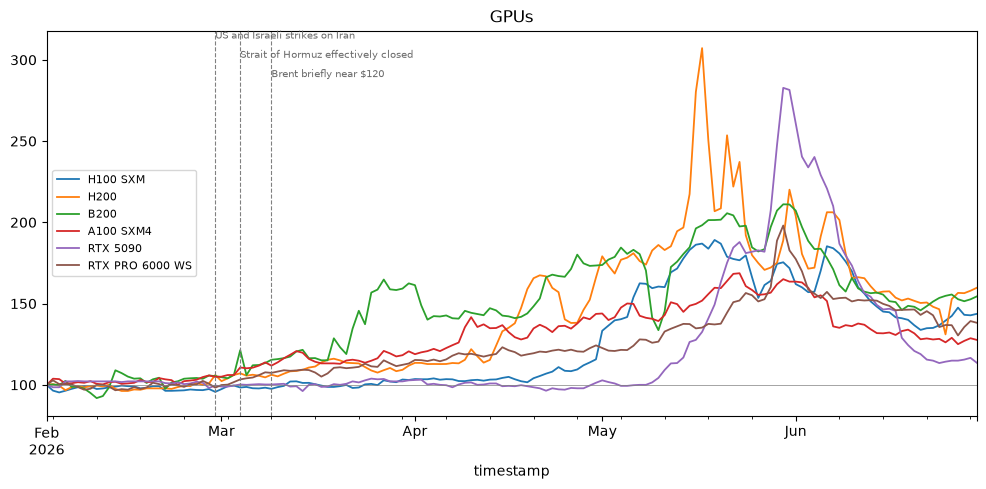

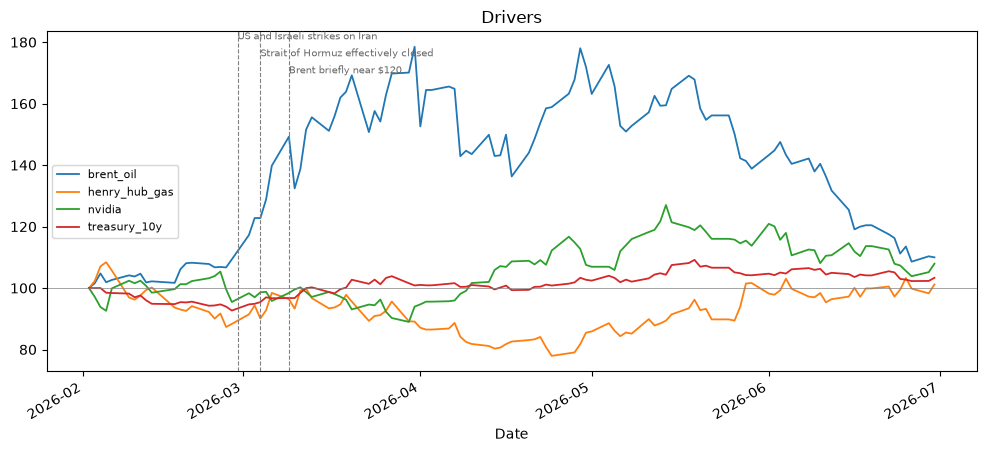

In [15]:
WINDOW = ("2026-02-01", "2026-06-30")
events = load_events()
plot_window(gpus, *WINDOW, events, title="GPUs"); plt.show()
plot_window(drivers[["brent_oil", "henry_hub_gas", "nvidia", "treasury_10y"]], *WINDOW, events, title="Drivers"); plt.show()

In [16]:
pd.DataFrame({"% change over window": change_over(pd.concat([gpus, drivers], axis=1), *WINDOW)})

/var/folders/4r/f7k5gh050q3_v7khjwbtg6mr0000gn/T/ipykernel_58155/683903390.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  pd.DataFrame({"% change over window": change_over(pd.concat([gpus, drivers], axis=1), *WINDOW)})


,% change over window
H100 SXM,43.7
H200,59.7
B200,54.4
A100 SXM4,27.7
RTX 5090,13.6
RTX PRO 6000 WS,38.2
henry_hub_gas,-24.8
wti_oil,6.6
brent_oil,3.2
nvidia,4.8


## 7 · Utilization: is the market running out of capacity?
Utilization = share of Ornn's tracked GPUs that are rented (0 to 1). The idea being tested: **prices stay flat while there's spare capacity, then jump once the market is nearly full. The vertical line is 85% utilizzation**

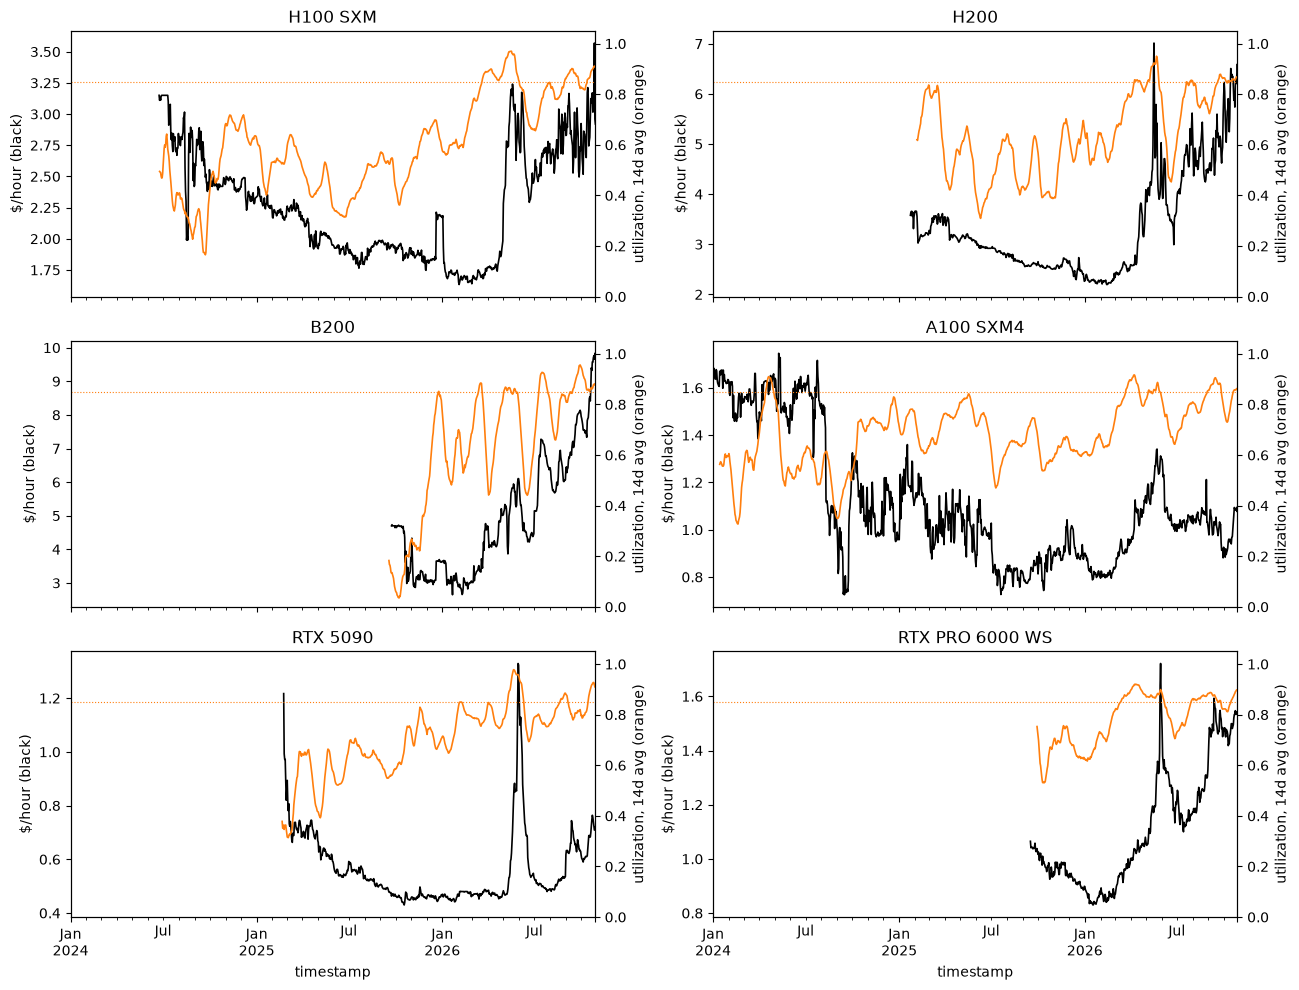

In [20]:
util = load_utilization()
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
for ax, g in zip(axes.flat, gpus.columns):
    gpus[g].plot(ax=ax, color='black', lw=1.2, title=g)
    ax2 = ax.twinx(); util[g].rolling(14).mean().plot(ax=ax2, color='tab:orange', lw=1.2)
    ax2.axhline(0.85, color='tab:orange', ls=':', lw=0.8); ax2.set_ylim(0, 1.05)
    ax.set_ylabel('$/hour (black)'); ax2.set_ylabel('utilization, 14d avg (orange)')
fig.tight_layout(); plt.show(); 

### Monthly view
Utilization next to price (price as a multiple of its Dec 2025–Jan 2026 level).

In [16]:
um, pm = util.resample("ME").mean(), gpus.resample("ME").mean()
rows = {}
for g in gpus.columns:
    rows[(g, "utilization")] = um[g]
    rows[(g, "price vs Dec-Jan")] = pm[g] / pm[g].loc["2025-12":"2026-01"].mean()
monthly = pd.DataFrame(rows).T.loc[:, "2025-09":]
monthly.columns = [c.strftime("%b %y") for c in monthly.columns]
monthly.round(2)

Sep 25  Oct 25  Nov 25  Dec 25  Jan 26  \
H100 SXM        utilization         0.50    0.47    0.62    0.64    0.59   
                price vs Dec-Jan    1.05    1.02    1.00    1.05    0.95   
H200            utilization         0.53    0.40    0.62    0.62    0.59   
                price vs Dec-Jan    1.09    1.07    1.10    1.04    0.96   
B200            utilization         0.13    0.18    0.31    0.75    0.58   
                price vs Dec-Jan    1.45    1.28    0.99    1.01    0.99   
A100 SXM4       utilization         0.70    0.57    0.65    0.61    0.64   
                price vs Dec-Jan    0.93    0.98    1.05    1.05    0.95   
RTX 5090        utilization         0.57    0.69    0.76    0.71    0.73   
                price vs Dec-Jan    1.06    0.99    1.01    1.00    1.00   
RTX PRO 6000 WS utilization         0.74    0.62    0.72    0.64    0.69   
                price vs Dec-Jan    1.18    1.10    1.09    1.03    0.97   

                                  Feb 26  Mar 26  Apr 26  May 26  Jun 26  \
H100 SXM        utilization         0.69    0.85    0.88    0.92    0.70   
                price vs Dec-Jan    0.90    0.92    0.97    1.53    1.40   
H200            utilization         0.59    0.75    0.84    0.87    0.54   
                price vs Dec-Jan    0.95    1.05    1.29    1.92    1.59   
B200            utilization         0.62    0.70    0.73    0.84    0.54   
                price vs Dec-Jan    0.90    1.14    1.36    1.65    1.44   
A100 SXM4       utilization         0.68    0.85    0.85    0.85    0.69   
                price vs Dec-Jan    0.93    1.04    1.20    1.39    1.24   
RTX 5090        utilization         0.80    0.80    0.78    0.93    0.77   
                price vs Dec-Jan    1.04    1.03    1.02    1.52    1.63   
RTX PRO 6000 WS utilization         0.76    0.87    0.90    0.88    0.76   
                price vs Dec-Jan    0.98    1.07    1.17    1.39    1.46   

                                  Jul 26  Aug 26  Sep 26  Oct 26  
H100 SXM        utilization         0.81    0.82    0.86    0.88  
                price vs Dec-Jan    1.41    1.49    1.52    1.55  
H200            utilization         0.82    0.75    0.85    0.86  
                price vs Dec-Jan    1.93    1.98    2.05    2.47  
B200            utilization         0.87    0.76    0.90    0.87  
                price vs Dec-Jan    1.97    1.89    2.23    2.48  
A100 SXM4       utilization         0.78    0.81    0.86    0.82  
                price vs Dec-Jan    1.18    1.21    1.14    1.10  
RTX 5090        utilization         0.77    0.85    0.80    0.88  
                price vs Dec-Jan    1.10    1.12    1.43    1.41  
RTX PRO 6000 WS utilization         0.81    0.87    0.85    0.86  
                price vs Dec-Jan    1.31    1.40    1.69    1.67

### Which came first in 2026: full capacity or higher prices?
Positive `days_util_first` = utilization reached 85% before the price rose 30%.

In [17]:
utilization_timing(gpus, util)

,util_reached_85%,price_up_30%,days_util_first
H100 SXM,2026-03-20,2026-05-01,42
H200,2026-04-09,2026-04-15,6
B200,2026-03-13,2026-03-23,10
A100 SXM4,2026-03-23,2026-04-09,17
RTX 5090,2026-02-07,2026-05-17,99
RTX PRO 6000 WS,2026-03-13,2026-05-11,59


### Price at different utilization levels
Median price per utilization band. A flat-then-steep pattern = scarcity pricing. Caution: low-utilization days are mostly from 2024–25 when prices were also drifting down, so this mixes time periods.

In [18]:
bands = [0, .6, .7, .8, .85, .9, .95, 1.001]
pd.DataFrame({g: pd.concat([gpus[g], util[g]], axis=1, keys=["p", "u"]).dropna()
                 .pipe(lambda d: d.groupby(pd.cut(d.u, bands), observed=True)["p"].median())
              for g in gpus.columns}).round(2)

,H100 SXM,H200,B200,A100 SXM4,RTX 5090,RTX PRO 6000 WS
u,,,,,,
"(0.0, 0.6]",2.04,2.72,3.66,1.10,0.56,0.94
"(0.6, 0.7]",2.24,2.84,3.70,0.96,0.52,0.94
"(0.7, 0.8]",2.47,3.10,4.44,1.05,0.48,0.98
"(0.8, 0.85]",2.68,4.17,5.28,1.05,0.48,1.17
"(0.85, 0.9]",2.70,4.52,5.77,1.06,0.51,1.17
"(0.9, 0.95]",2.80,4.76,6.09,1.03,0.68,1.08
"(0.95, 1.001]",2.83,4.47,6.94,1.62,0.63,1.52


## 8 · Hourly: any immediate reaction to oil or gas?
Tests a *fast* channel (same-hour to 3-day reactions), not the slow cost channel. Hourly Ornn prices move in $0.01 steps and change in about 57% of hours. Oil/gas hours outside trading time drop out. `chance_any_lag_%` slides the energy series to random start points (300 times) and keeps the strongest correlation across all 97 lags.

In [19]:
from ornn_analysis.data import load_ornn_hourly, load_yahoo_hourly
LAGS = list(range(-24, 73))   # positive = energy moved first (hours)
energy_h = {"wti": load_yahoo_hourly("CL=F"), "brent": load_yahoo_hourly("BZ=F"), "gas": load_yahoo_hourly("NG=F")}
rows = []
for g in ["H100 SXM", "H200", "B200"]:
    s = load_ornn_hourly(g)
    hours = pd.date_range(s.index.min(), s.index.max(), freq="h")
    y = np.log(s.reindex(hours).ffill()).diff()
    for name, e in energy_h.items():
        x = np.log(e.reindex(hours)).diff()
        corrs = pd.Series({k: y.corr(x.shift(k)) for k in LAGS})
        best = corrs.abs().idxmax()
        xv, rng, hits = x.dropna(), np.random.default_rng(0), 0
        for _ in range(300):
            xs = pd.Series(np.roll(xv.values, rng.integers(500, len(xv) - 500)), xv.index).reindex(hours)
            hits += max(abs(y.corr(xs.shift(k))) for k in LAGS) >= abs(corrs[best])
        n = pd.concat([y, x], axis=1).dropna().shape[0]
        rows.append({"gpu": g, "energy": name, "hours": n, "same_hour": corrs[0], "plus_24h": corrs[24],
                     "strongest_lag_h": best, "strongest_corr": corrs[best], "noise_band": 2 / np.sqrt(n), "chance_any_lag_%": 100 * hits / 300})
pd.DataFrame(rows).round(3)

,gpu,energy,hours,same_hour,plus_24h,strongest_lag_h,strongest_corr,noise_band,chance_any_lag_%
0,H100 SXM,wti,12600,3.00e-03,1.70e-02,26,-0.03,0.02,23.00
1,H100 SXM,brent,12688,1.20e-02,1.00e-03,5,-0.03,0.02,20.33
2,H100 SXM,gas,12588,-3.00e-03,-4.00e-03,39,0.02,0.02,80.33
3,H200,wti,9509,9.00e-03,-2.00e-03,-4,-0.03,0.02,50.33
4,H200,brent,9555,3.00e-03,1.00e-03,-14,-0.03,0.02,27.67
5,H200,gas,9489,-7.00e-03,6.00e-03,-18,0.02,0.02,75.00
6,B200,wti,5898,2.80e-02,-1.00e-03,70,-0.04,0.03,17.67
7,B200,brent,5871,2.90e-02,2.00e-03,70,-0.03,0.03,65.33
8,B200,gas,5891,8.00e-03,3.00e-03,55,-0.03,0.03,53.33


## 9 · Supply: data-center construction (Census)
Monthly US private construction spending on data centers (Census C30, seasonally adjusted annual rate, from 2014). Spending happens *while* facilities are built, so capacity comes online months later. The idea being tested: **when construction growth slows, the market tightens later.**

Caveats: it's in dollars (includes construction-cost inflation), it's mostly hyperscalers building for their own use rather than the rental market Ornn tracks, and the latest months are preliminary and get revised.

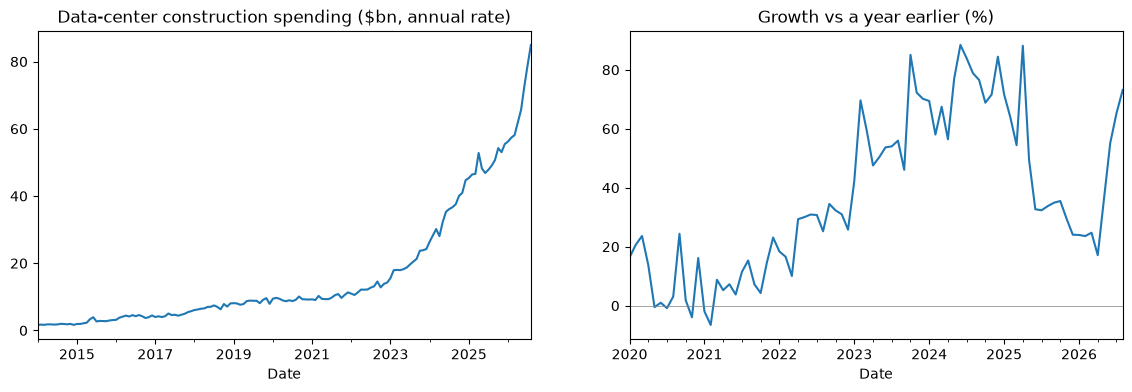

In [20]:
from ornn_analysis.data import load_census_construction
dc = load_census_construction("Data center")
dc_growth = 100 * dc.pct_change(12)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
(dc / 1000).plot(ax=a1, title="Data-center construction spending ($bn, annual rate)")
dc_growth.loc["2020":].plot(ax=a2, title="Growth vs a year earlier (%)"); a2.axhline(0, color="grey", lw=0.5)
plt.show()

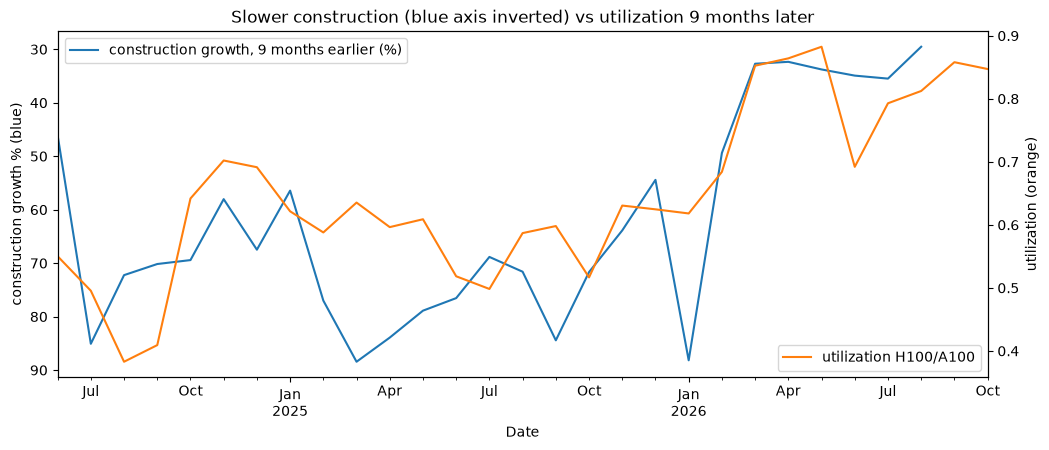

In [21]:
LAG = 9   # months; the strongest lag found, consistent across GPUs
util_m = util.resample("MS").mean()
fig, ax = plt.subplots(figsize=(12, 4.5))
dc_growth.shift(LAG).loc["2024-06":].plot(ax=ax, color="tab:blue", label=f"construction growth, {LAG} months earlier (%)")
ax.set_ylabel("construction growth % (blue)"); ax.invert_yaxis(); ax.legend(loc="upper left")
ax2 = ax.twinx(); util_m[["H100 SXM", "A100 SXM4"]].mean(axis=1).loc["2024-06":].plot(ax=ax2, color="tab:orange", label="utilization H100/A100")
ax2.set_ylabel("utilization (orange)"); ax2.legend(loc="lower right")
ax.set_title(f"Slower construction (blue axis inverted) vs utilization {LAG} months later"); plt.show()

In [22]:
pd.DataFrame({g: {**{f"{k}m": util_m[g].loc["2024-06":].corr(dc_growth.shift(k)) for k in [0, 3, 6, 9, 12]},
                  "months": util_m[g].loc["2024-06":].count()} for g in util_m.columns}).T.round(2)

,0m,3m,6m,9m,12m,months
H100 SXM,-0.32,-0.65,-0.69,-0.78,-0.26,29.0
H200,0.07,-0.26,-0.54,-0.61,-0.41,22.0
B200,0.21,-0.47,-0.81,-0.74,-0.38,14.0
A100 SXM4,-0.18,-0.39,-0.33,-0.47,-0.03,29.0
RTX 5090,-0.34,-0.72,-0.77,-0.78,-0.34,21.0
RTX PRO 6000 WS,0.22,-0.56,-0.56,-0.75,-0.39,14.0


In [23]:
# Robustness: chance test across lags -12..18, a version using changes, and a version without 2026
u = util_m[["H100 SXM", "A100 SXM4"]].mean(axis=1).loc["2024-06":]
scan = lambda x: pd.Series({k: u.corr(x.shift(k)) for k in range(-12, 19)})
real = scan(dc_growth); xv = dc_growth.dropna(); rng = np.random.default_rng(0)
hits = np.mean([scan(pd.Series(np.roll(xv.values, rng.integers(12, len(xv) - 12)), xv.index)).abs().max() >= abs(real[LAG]) for _ in range(2000)])
print(f"lag {LAG}: corr {real[LAG]:.2f}; chance of this strength at any lag: {hits:.1%}")
print("3-month changes, by lag:", {k: round(u.diff(3).corr(dc_growth.diff(3).shift(k)), 2) for k in [0, 3, 6, 9, 12]})
print(f"without 2026: {u.loc[:'2025-12'].corr(dc_growth.shift(LAG)):.2f}")

lag 9: corr -0.71; chance of this strength at any lag: 0.7%
3-month changes, by lag: {0: np.float64(-0.0), 3: np.float64(-0.09), 6: np.float64(0.14), 9: np.float64(-0.49), 12: np.float64(0.29)}
without 2026: -0.16


## 10 · Memory: Ornn DDR5 prices
Memory is the other supply constraint: HBM (the memory on GPUs) is made on the same production lines as regular DRAM, so a DRAM shortage limits how many GPUs can be built. Ornn tracks commodity DRAM spot prices (not HBM itself, but the same shortage).

Three questions: **when** did memory prices take off, did the market price memory into GPUs (the H200/H100 ratio: same chip, more memory), and do memory prices **lead** GPU prices week to week?

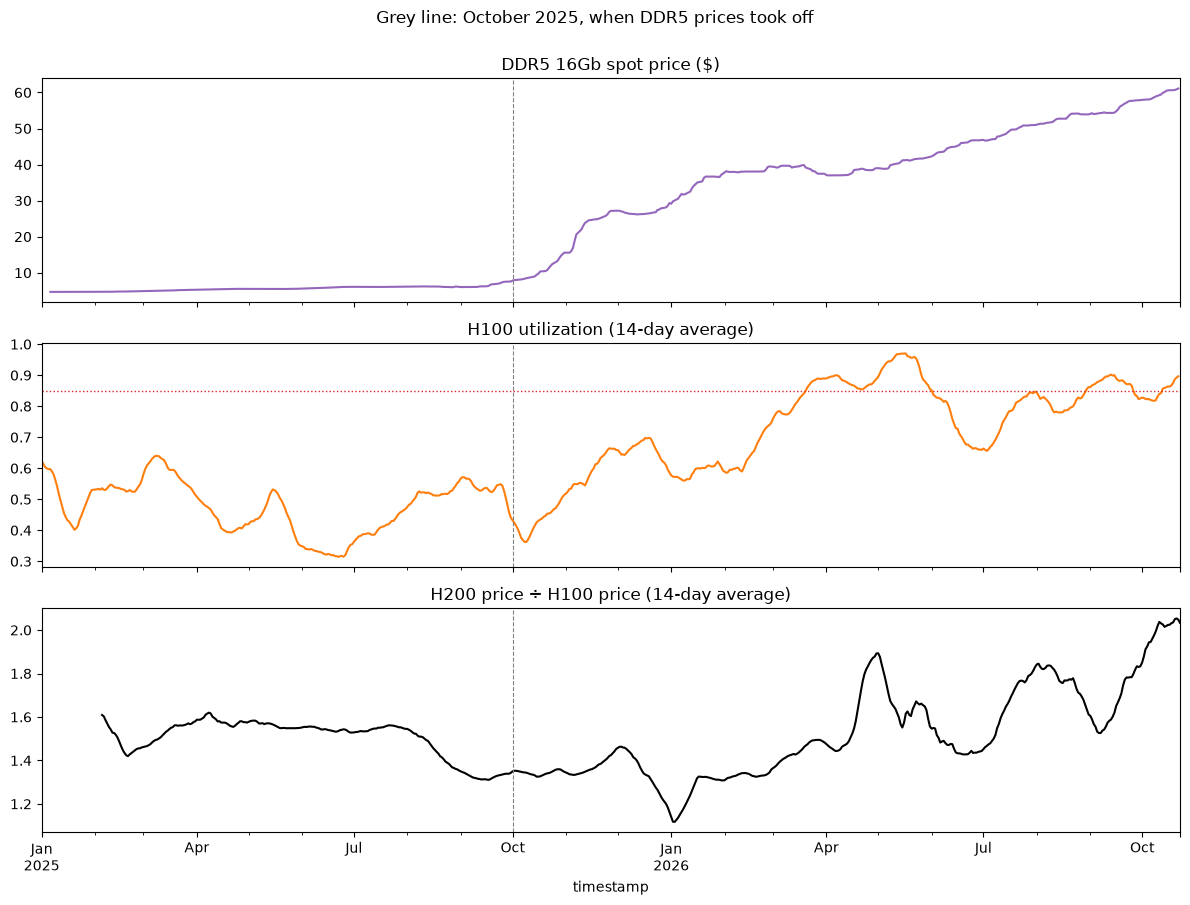

In [24]:
from ornn_analysis.data import load_ornn_memory
from ornn_analysis.series import MEMORY
mem = pd.DataFrame({name: load_ornn_memory(memory_id) for name, memory_id in MEMORY.items()})
ddr5 = mem["DDR5 16Gb chip"]
h200_ratio = gpus["H200"] / gpus["H100 SXM"]
START = "2025-01-01"
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ddr5.loc[START:].plot(ax=axes[0], color="tab:purple", title="DDR5 16Gb spot price ($)")
util["H100 SXM"].rolling(14).mean().loc[START:].plot(ax=axes[1], color="tab:orange", title="H100 utilization (14-day average)")
axes[1].axhline(0.85, color="tab:red", ls=":", lw=1)
h200_ratio.rolling(14).mean().loc[START:].plot(ax=axes[2], color="black", title="H200 price ÷ H100 price (14-day average)")
for ax in axes:
    ax.axvline(pd.Timestamp("2025-10-01"), color="grey", ls="--", lw=0.8)
fig.suptitle("Grey line: October 2025, when DDR5 prices took off", y=1.0)
fig.tight_layout(); plt.show()

### Monthly view
DDR5 price and its month-on-month change, next to H100 utilization and the H200/H100 ratio.

In [25]:
monthly = pd.DataFrame({
    "DDR5 16Gb ($)": ddr5.resample("ME").mean(),
    "DDR5 change vs previous month (%)": 100 * ddr5.resample("ME").mean().pct_change(),
    "H100 utilization": util["H100 SXM"].resample("ME").mean(),
    "H200 / H100": h200_ratio.resample("ME").mean(),
}).loc["2025-06":]
monthly.index = monthly.index.strftime("%b %y")
monthly.T.round(2)

,Jun 25,Jul 25,Aug 25,Sep 25,Oct 25,Nov 25,Dec 25,Jan 26,Feb 26,Mar 26,Apr 26,May 26,Jun 26,Jul 26,Aug 26,Sep 26,Oct 26
DDR5 16Gb ($),5.95,6.07,6.12,6.61,10.86,23.15,26.97,34.12,38.21,38.98,37.83,40.58,44.99,49.03,52.84,55.61,59.49
DDR5 change vs previous month (%),8.05,2.02,0.70,8.10,64.32,113.11,16.49,26.53,11.96,2.01,-2.93,7.25,10.88,8.97,7.77,5.25,6.98
H100 utilization,0.34,0.44,0.53,0.50,0.47,0.62,0.64,0.59,0.69,0.85,0.88,0.92,0.70,0.81,0.82,0.86,0.88
H200 / H100,1.54,1.55,1.41,1.33,1.34,1.40,1.27,1.30,1.35,1.46,1.69,1.60,1.45,1.74,1.70,1.73,2.04


In [26]:
d = ddr5.dropna(); latest = d.index[-1]
year_ago = d.asof(latest - pd.Timedelta(days=365))
print(f"DDR5 16Gb: ${d.iloc[-1]:.2f} on {latest.date()}, {100 * (d.iloc[-1] / year_ago - 1):+.0f}% vs a year earlier")
print(f"DDR5 server module (RDIMM 32GB): ${mem['DDR5 server module (RDIMM 32GB)'].dropna().iloc[-1]:,.0f} "
      f"(series starts {mem['DDR5 server module (RDIMM 32GB)'].first_valid_index().date()})")

DDR5 16Gb: $61.10 on 2026-10-22, +442% vs a year earlier
DDR5 server module (RDIMM 32GB): $2,185 (series starts 2025-11-24)


### Do memory prices lead GPU prices?
**Week to week:** weekly % changes in DDR5 against weekly changes in the H200/H100 ratio and the H200 price, with DDR5 0-12 weeks earlier, plus the chance test (section 5).

**Month to month:** the DDR5 level against the H200/H100 ratio with DDR5 0-6 months earlier. Both rose in 2026, so this mostly shows the *delay* within one cycle, not proof of a link.

In [27]:
w = pd.DataFrame({"ddr5": ddr5, "ratio": h200_ratio, "H200": gpus["H200"]}).ffill().resample("W-FRI").last()
w = w.pct_change(fill_method=None).loc["2025-01":] * 100
for target in ["ratio", "H200"]:
    lc = lag_correlations(w[target], w[["ddr5"]], lags=range(0, 13)).loc["ddr5"]
    best = int(lc.abs().idxmax())
    print(f"{target}: correlation by weeks DDR5 earlier", lc.round(2).to_dict())
    print(f"   strongest at {best} weeks:", chance_test(w[target], w["ddr5"], best, n=1000))
lv = pd.DataFrame({"ddr5": np.log(ddr5.resample("ME").mean()), "ratio": h200_ratio.resample("ME").mean()}).loc["2025-02":]
print("\nMonthly levels, H200/H100 ratio vs DDR5 k months earlier:", {k: round(lv.ratio.corr(lv.ddr5.shift(k)), 2) for k in range(0, 7)})

ratio: correlation by weeks DDR5 earlier {0: 0.05, 1: 0.03, 2: 0.04, 3: 0.03, 4: -0.06, 5: -0.05, 6: -0.04, 7: -0.16, 8: -0.03, 9: 0.08, 10: -0.01, 11: 0.04, 12: 0.13}


   strongest at 7 weeks: {'corr': np.float64(-0.16), 'chance_at_this_lag_%': np.float64(3.2), 'chance_at_any_lag_%': np.float64(62.8)}
H200: correlation by weeks DDR5 earlier {0: -0.01, 1: -0.02, 2: -0.01, 3: -0.05, 4: -0.07, 5: -0.1, 6: -0.1, 7: -0.1, 8: -0.07, 9: -0.05, 10: -0.1, 11: -0.03, 12: -0.0}


   strongest at 6 weeks: {'corr': np.float64(-0.1), 'chance_at_this_lag_%': np.float64(25.6), 'chance_at_any_lag_%': np.float64(98.5)}

Monthly levels, H200/H100 ratio vs DDR5 k months earlier: {0: np.float64(0.32), 1: np.float64(0.39), 2: np.float64(0.5), 3: np.float64(0.63), 4: np.float64(0.73), 5: np.float64(0.8), 6: np.float64(0.83)}


### Were memory-maker shares a good stand-in?
Earlier versions used Micron, SK hynix and Samsung share prices as a proxy for memory prices. Compared with Ornn's actual DDR5 prices, week to week:

In [28]:
basket = (drivers[["micron", "sk_hynix", "samsung"]].ffill() / drivers[["micron", "sk_hynix", "samsung"]].ffill().loc["2024-06-03"]).mean(axis=1)
wk = pd.DataFrame({"ddr5": ddr5, "memory_shares": basket}).ffill().resample("W-FRI").last().pct_change(fill_method=None).loc["2025-01":]
print(f"Weekly correlation, DDR5 spot vs memory-maker shares: {wk.ddr5.corr(wk.memory_shares):.2f}")

Weekly correlation, DDR5 spot vs memory-maker shares: 0.16


## 11 · Weekly and daily cycles
Each day (or hour) compared with its own surrounding 7-day (24-hour) average, so trends drop out. `p_value` is a Kruskal-Wallis test: do the weekdays (hours) differ at all?

Power prices and compute demand both peak on weekday afternoons, so timing alone can't separate them. Utilization measures demand directly, and weekends help: power still peaks in the afternoon on weekends, business demand doesn't.

In [29]:
from scipy.stats import kruskal
from ornn_analysis.data import load_ornn_hourly
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
def weekday_profile(s, log=True):
    s = s.dropna().asfreq("D"); x = np.log(s) if log else s
    dev = (x - x.rolling(7, center=True).mean()).dropna() * 100
    groups = [dev[dev.index.day_name() == d] for d in DAYS]
    return pd.Series([g_.mean() for g_ in groups] + [kruskal(*groups).pvalue], index=[d[:3] for d in DAYS] + ["p_value"])
print("Price: % deviation from own 7-day average"); display(pd.DataFrame({c: weekday_profile(gpus[c]) for c in gpus}).T.round(2))
print("Utilization: percentage-point deviation from own 7-day average"); display(pd.DataFrame({c: weekday_profile(util[c], log=False) for c in util}).T.round(2))

Price: % deviation from own 7-day average


,Mon,Tue,Wed,Thu,Fri,Sat,Sun,p_value
H100 SXM,-0.07,0.14,0.08,0.10,0.29,-0.16,-0.41,0.28
H200,-0.44,-0.72,-0.26,0.14,0.60,0.67,0.07,0.03
B200,-0.64,-0.16,0.37,0.22,0.24,0.14,-0.30,0.27
A100 SXM4,-0.48,0.19,0.29,0.31,0.76,-0.18,-0.92,0.00
RTX 5090,-0.25,0.01,-0.05,0.06,-0.04,0.12,-0.01,0.72
RTX PRO 6000 WS,-0.14,-0.25,-0.03,0.36,0.40,-0.02,-0.35,0.00


Utilization: percentage-point deviation from own 7-day average


,Mon,Tue,Wed,Thu,Fri,Sat,Sun,p_value
H100 SXM,-0.92,0.21,1.56,2.05,1.33,-1.71,-2.68,0.0
H200,-0.74,1.56,2.19,2.17,1.21,-2.67,-3.65,0.0
B200,1.04,0.75,1.48,2.06,0.83,-3.29,-3.03,0.0
A100 SXM4,-0.01,2.36,2.36,1.62,0.11,-3.30,-3.17,0.0
RTX 5090,-0.89,0.49,1.18,1.02,0.67,-0.66,-1.87,0.0
RTX PRO 6000 WS,0.03,0.48,1.96,2.43,1.08,-2.43,-3.48,0.0


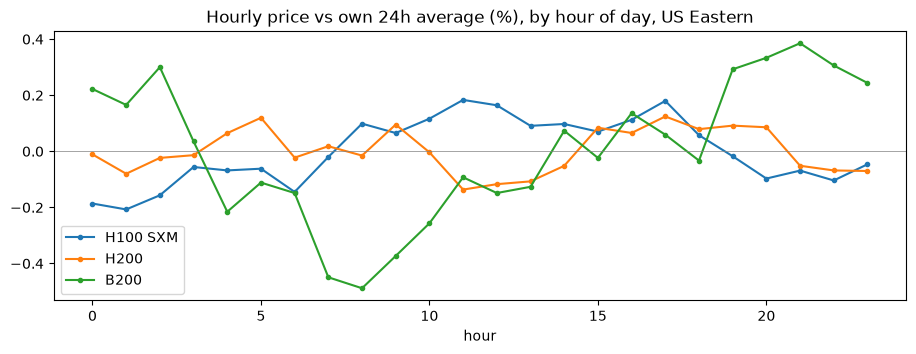

H100 daytime bump (9-17h minus 0-6h ET): weekdays +0.32%, weekends +0.06%; summer weekdays +0.58%, other weekdays +0.21%


In [30]:
def hourly_dev(gpu):
    s = load_ornn_hourly(gpu).asfreq("h").ffill()
    dev = ((np.log(s) - np.log(s).rolling(24, center=True).mean()) * 100).dropna()
    et = dev.index.tz_localize("UTC").tz_convert("US/Eastern")
    return pd.DataFrame({"dev": dev.values, "hour": et.hour, "weekend": et.dayofweek >= 5, "month": et.month})
profiles = {g_: hourly_dev(g_) for g_ in ["H100 SXM", "H200", "B200"]}
ax = pd.DataFrame({g_: d.groupby("hour").dev.mean() for g_, d in profiles.items()}).plot(figsize=(11, 3.5), marker="o", ms=3,
        title="Hourly price vs own 24h average (%), by hour of day, US Eastern")
ax.axhline(0, color="grey", lw=0.5); plt.show()
bump = lambda d: d[d.hour.between(9, 17)].dev.mean() - d[d.hour.between(0, 6)].dev.mean()
d = profiles["H100 SXM"]
print(f"H100 daytime bump (9-17h minus 0-6h ET): weekdays {bump(d[~d.weekend]):+.2f}%, weekends {bump(d[d.weekend]):+.2f}%;"
      f" summer weekdays {bump(d[~d.weekend & d.month.isin([6, 7, 8])]):+.2f}%, other weekdays {bump(d[~d.weekend & ~d.month.isin([6, 7, 8])]):+.2f}%")